# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Яцишин Роман'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 19       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Яцишин Роман | ШІ-32 | номер 19


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 19   ·   Яцишин Роман   ·   ШІ-32

   Ринок:  Chernivtsi
   Товар:  гречка   (у наборі даних: Buckwheat grits - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import pandas as pd

df = pd.read_csv("ціни_україна_2014_2017.csv")

data = df[(df["ринок"] == MARKET) & (df["товар"] == GOOD)].copy()

data["date"] = pd.to_datetime(
    dict(year=data["рік"], month=data["місяць"], day=1)
)

monthly_grid = pd.date_range("2014-03-01", "2017-12-01", freq="MS")

ts = data.set_index("date")["ціна"].sort_index().reindex(monthly_grid)
ts.index.name = "date"

missing = ts[ts.isna()].index

print("Місяців у сітці:", len(ts))
print("Місяців із вимірами:", ts.count())
print("Кількість пропусків:", ts.isna().sum())
print("Пропущений місяць:", missing.strftime("%Y-%m").tolist())

for date in missing:
    count = len(df[(df["рік"] == date.year) & (df["місяць"] == date.month)])
    print("Записів за пропущений місяць у всьому наборі:", count)

print("\nПерші значення ряду:")
print(ts.head())


Місяців у сітці: 46
Місяців із вимірами: 45
Кількість пропусків: 1
Пропущений місяць: ['2017-08']
Записів за пропущений місяць у всьому наборі: 0

Перші значення ряду:
date
2014-03-01    7.4133
2014-04-01    7.8833
2014-05-01    8.0833
2014-06-01    8.1267
2014-07-01    7.9067
Freq: MS, Name: ціна, dtype: float64


**Висновок до завдання 1:**

Ряд цін на гречку на ринку Chernivtsi приведено до повної місячної сітки з березня 2014 по грудень 2017 року. У сітці **46 місяців**, вимір мають **45**.

Пропущено **серпень 2017 року**. Причина не в моєму ряді, а в усьому наборі: за 2017-08 у файлі немає **жодного** запису для жодного ринку й товару (перевірка дала 0 записів). Тобто за цей місяць дані взагалі не потрапили до джерела.

Пропуск у ряді **один**. Пропущений місяць відсутній як рядок, а не як порожня клітинка. Тому без `reindex` на повну сітку `isna()` показав би 0 пропусків, і пропуск лишився б непоміченим.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску

missing_date = ts[ts.isna()].index[0]

ffill_value = ts.ffill().loc[missing_date]
linear_value = ts.interpolate(method="linear").loc[missing_date]
bfill_value = ts.bfill().loc[missing_date]

ts_filled = ts.interpolate(method="linear")

print("Пропущений місяць:", missing_date.strftime("%Y-%m"))
print(f"Перенесення попереднього значення: {ffill_value:.4f}")
print(f"Лінійна інтерполяція: {linear_value:.4f}")
print(f"Перенесення наступного значення: {bfill_value:.4f}")
print("Обраний метод: лінійна інтерполяція")
print("Пропусків після заповнення:", ts_filled.isna().sum())

Пропущений місяць: 2017-08
Перенесення попереднього значення: 23.4367
Лінійна інтерполяція: 22.7867
Перенесення наступного значення: 22.1367
Обраний метод: лінійна інтерполяція
Пропусків після заповнення: 0


**Висновок до завдання 2:**

| Спосіб | Значення за 08.2017, грн |
|---|---|
| перенесення попереднього (липень) | 23.4367 |
| лінійна інтерполяція | 22.7867 |
| перенесення наступного (вересень) | 22.1367 |

Обрано **лінійну інтерполяцію**. У 2017 році ціна рівномірно падала: 23.44 грн у липні, 22.14 грн у вересні. Перенесення липневого значення завищило б серпень, а перенесення вересневого — занизило б. Інтерполяція кладе точку посередині між сусідами, що відповідає рівномірному спаду. Пропуск лише один і стоїть усередині ряду, а не на краю, тож обидва сусіди відомі.

Заповнювати пропуск **неприпустимо**, коли даних бракує не за один місяць, а за довгий період, і ми не знаємо, що там відбувалося. Приклад із цього набору: Крим має дані лише за 03.2014, Севастополь — лише за 03–04.2014, після чого ці ринки зникають. Заповнити 44 місяці означало б **вигадати** ряд, якого не існувало. Будь-який аналіз такого ряду описував би метод заповнення, а не реальні ціни.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

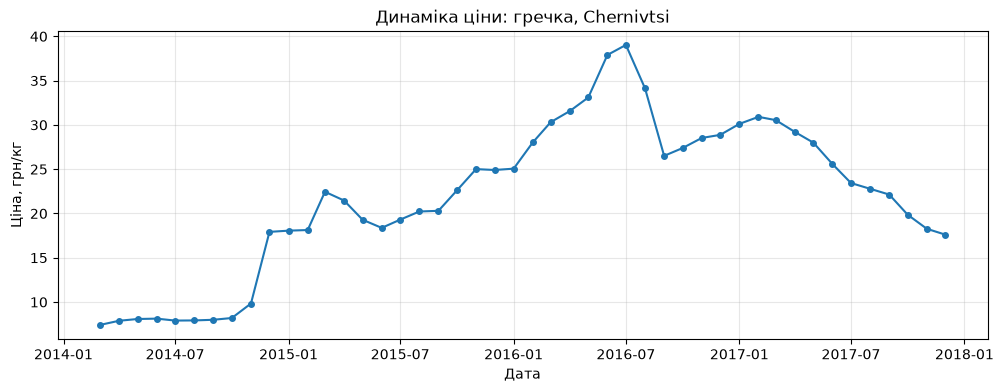

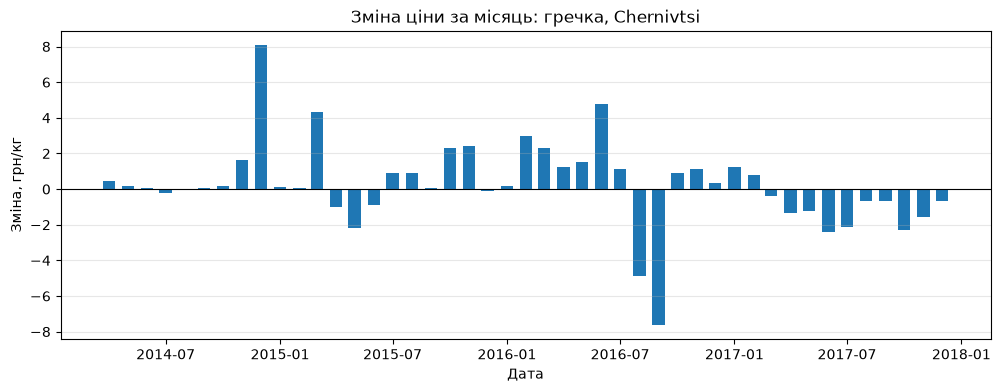

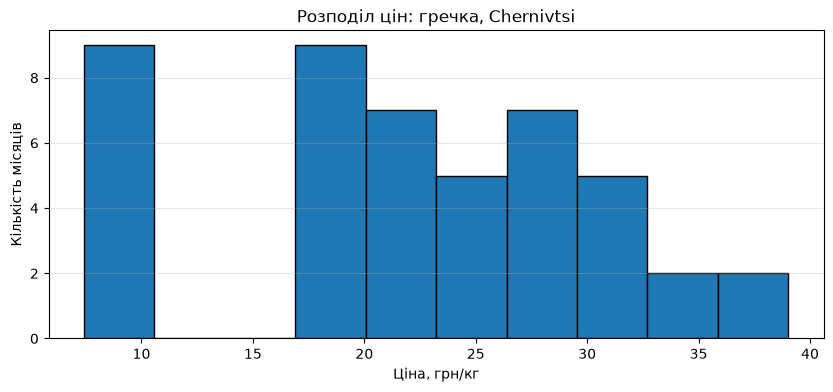

Найбільше зростання: 2014-12 8.09
Найбільше падіння: 2016-09 -7.6233


In [5]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

series = ts_filled.astype(float)
changes = series.diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(series.index, series.values, marker="o", markersize=4)
plt.title(f"Динаміка ціни: {GOOD_UA}, {MARKET}")
plt.xlabel("Дата")
plt.ylabel("Ціна, грн/кг")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
plt.bar(changes.index, changes.values, width=20)
plt.axhline(0, color="black", linewidth=0.8)
plt.title(f"Зміна ціни за місяць: {GOOD_UA}, {MARKET}")
plt.xlabel("Дата")
plt.ylabel("Зміна, грн/кг")
plt.grid(axis="y", alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(series.values, bins=10, edgecolor="black")
plt.title(f"Розподіл цін: {GOOD_UA}, {MARKET}")
plt.xlabel("Ціна, грн/кг")
plt.ylabel("Кількість місяців")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Найбільше зростання:", changes.idxmax().strftime("%Y-%m"),
      round(changes.max(), 4))
print("Найбільше падіння:", changes.idxmin().strftime("%Y-%m"),
      round(changes.min(), 4))

**Висновок до завдання 3:**

**Графік 1 — лінійний із маркерами.** *Питання:* як змінювалася ціна з часом? Лінія підходить, бо місяці йдуть по порядку і сусідні точки пов'язані. Нахил лінії одразу показує напрямок і швидкість зміни. Маркери показують, що за лінією стоять окремі місячні виміри (46 точок). Шкала лінійна, у гривнях: ціни лежать у межах 7–39 грн, тобто в межах одного порядку, і мене цікавить зміна саме в гривнях. Логарифмічна шкала тут нічого не додала б.

**Графік 2 — стовпчиковий графік місячних змін.** *Питання:* у які місяці ціна змінювалася найбільше і в який бік? Кожен стовпчик — окрема величина (зміна за один місяць), яку відкладено від нуля. Тому тут потрібні стовпчики, а не лінія: важливі довжина і знак кожного, а не зв'язок між сусідніми. Лінія нуля відділяє зростання від падіння. Шкала лінійна, бо зміни бувають і додатні, і від'ємні.

**Графік 3 — гістограма.** *Питання:* які рівні цін траплялися найчастіше? Тут час свідомо прибрано: гістограма рахує, скільки місяців ціна потрапляла в кожен інтервал. 10 інтервалів — компроміс для 46 значень: з меншою кількістю форма розподілу зливається, з більшою інтервали майже порожні.

**Неочікувана знахідка.** Гістограма розпалася на дві групи. 9 місяців ціна була близько 7–10 грн, потім ідуть ціни 17–39 грн, а **між 10 і 17 грн немає жодного місяця**. Ціна не росла поступово, а перестрибнула: у грудні 2014 року вона зросла на 8.09 грн за один місяць (з 9.83 до 17.92 грн, майже вдвічі). Друга несподіванка: ряд не зростає весь час. Після піку 39.03 грн у липні 2016 року ціна впала (найбільше падіння за місяць — −7.62 грн у вересні 2016), а з лютого 2017 року рівномірно знижувалася до 17.61 грн у грудні 2017.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [6]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.3 MB 10.1 MB/s eta 0:00:02
   ------------ --------------------------- 3.7/11.3 MB 9.1 MB/s eta 0:00:01
   ---------------------- ----------------- 6.3/11.3 MB 10.4 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.3 MB 10.5 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 10.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 10.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


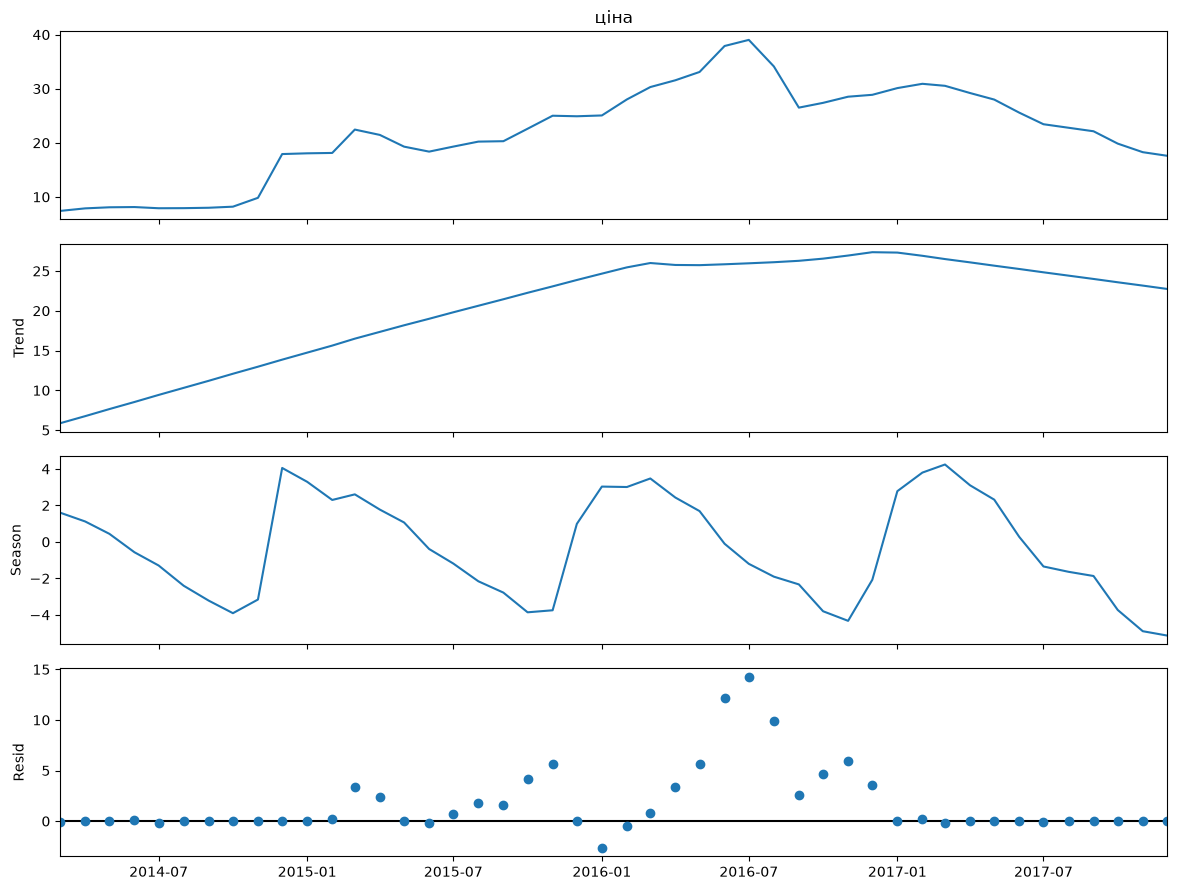

Сила сезонності Fs: 0.2395
Сила тренду Ft: 0.8376
Порогове значення: 0.6
Сезонність: слабка
Тренд: виражений


In [7]:
# Завдання 4. Розкладання на складові
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

stl = STL(ts_filled, period=12, robust=True).fit()

fig = stl.plot()
fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()

resid = stl.resid
seasonal = stl.seasonal
trend = stl.trend

Fs = max(0, 1 - np.var(resid) / np.var(seasonal + resid))
Ft = max(0, 1 - np.var(resid) / np.var(trend + resid))

print(f"Сила сезонності Fs: {Fs:.4f}")
print(f"Сила тренду Ft: {Ft:.4f}")
print("Порогове значення: 0.6")
print("Сезонність:", "виражена" if Fs >= 0.6 else "слабка")
print("Тренд:", "виражений" if Ft >= 0.6 else "слабкий")


**Висновок до завдання 4:**

Ряд розкладено методом STL з періодом 12 на тренд, сезонну складову й залишок.

* Сила сезонності: $F_S = \max\left(0,\ 1 - \frac{Var(R)}{Var(S+R)}\right) = $ **0.2395**
* Сила тренду: $F_T = \max\left(0,\ 1 - \frac{Var(R)}{Var(T+R)}\right) = $ **0.8376**

Порогове значення — 0.6. $F_S = 0.24 < 0.6$, тому **значущої сезонності в ряді немає**. STL намалював сезонну хвилю приблизно ±4 грн лише тому, що він виділяє сезонну складову завжди. Залишок при цьому значно більший (до 14 грн у середині 2016 року), отже ця «сезонність» пояснює малу частку коливань. До того ж хвиля сформована разовими стрибками (грудень 2014, початок 2016 року), а не повторюваними щорічними коливаннями.

$F_T = 0.84 > 0.6$, тобто **тренд виражений**. Проте він не монотонний: тренд зростає до 2016 року, а потім повільно спадає. Головне в ряді — зміни рівня, а не сезон.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

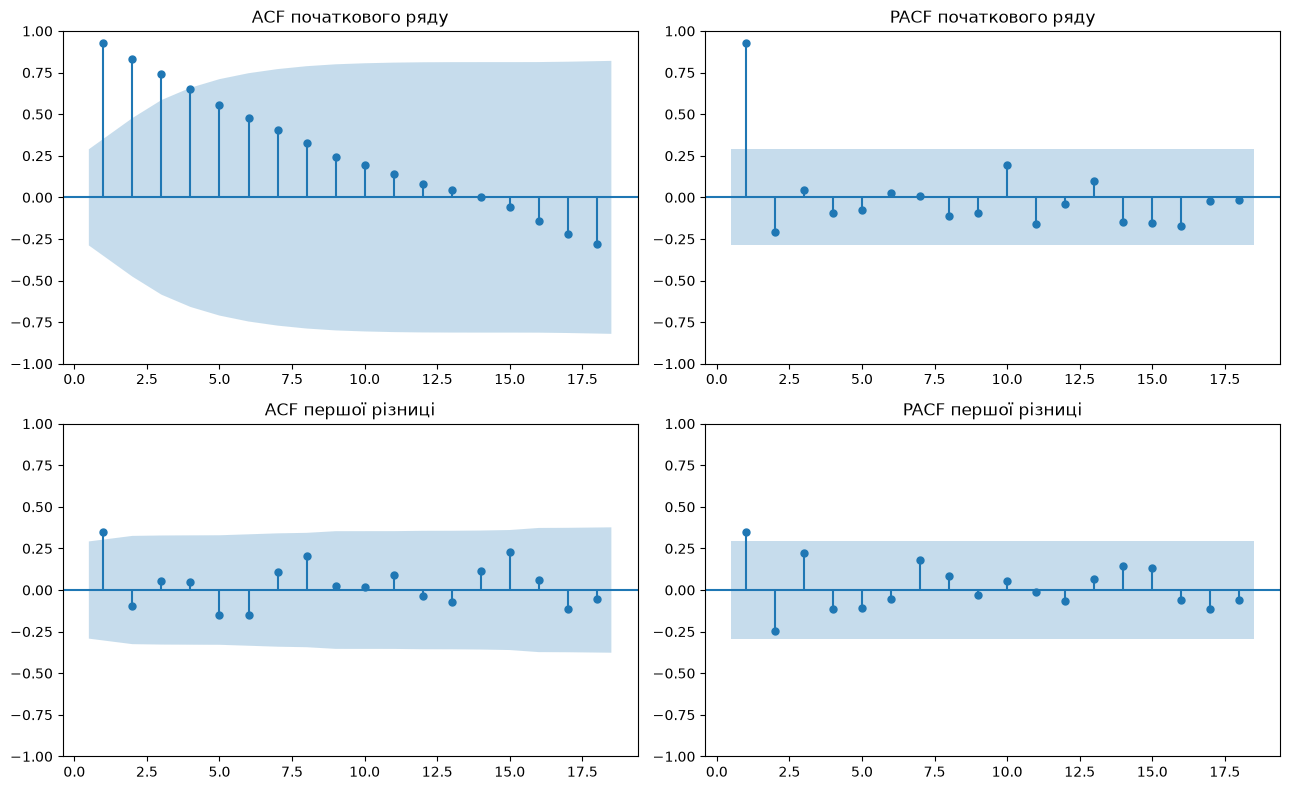

C:\Users\1\AppData\Local\Temp\ipykernel_7028\3475083874.py:29: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(data, autolag="AIC")[1]
C:\Users\1\AppData\Local\Temp\ipykernel_7028\3475083874.py:29: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(data, autolag="AIC")[1]


,Ряд,ADF p-value,KPSS p-value,ADF,KPSS
0,Початковий ряд,0.3265,0.0208,Нестаціонарний,Нестаціонарний
1,Перша різниця,0.0544,0.0744,Нестаціонарний,Стаціонарний


In [8]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings

ts_diff = ts_filled.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

plot_acf(ts_filled, lags=18, ax=axes[0, 0], zero=False)
axes[0, 0].set_title("ACF початкового ряду")

plot_pacf(ts_filled, lags=18, ax=axes[0, 1], zero=False)
axes[0, 1].set_title("PACF початкового ряду")

plot_acf(ts_diff, lags=18, ax=axes[1, 0], zero=False)
axes[1, 0].set_title("ACF першої різниці")

plot_pacf(ts_diff, lags=18, ax=axes[1, 1], zero=False)
axes[1, 1].set_title("PACF першої різниці")

plt.tight_layout()
plt.show()

results = []

for name, data in [("Початковий ряд", ts_filled),
                   ("Перша різниця", ts_diff)]:
    adf_p = adfuller(data, autolag="AIC")[1]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(data, regression="c", nlags="auto")[1]

    results.append({
        "Ряд": name,
        "ADF p-value": round(adf_p, 4),
        "KPSS p-value": round(kpss_p, 4),
        "ADF": "Стаціонарний" if adf_p < 0.05 else "Нестаціонарний",
        "KPSS": "Стаціонарний" if kpss_p >= 0.05 else "Нестаціонарний"
    })

display(pd.DataFrame(results))

**Висновок до завдання 5:**

| Ряд | ADF p | KPSS p | ADF каже | KPSS каже |
|---|---|---|---|---|
| вихідний | 0.3265 | 0.0208 | нестаціонарний | нестаціонарний |
| перша різниця | 0.0544 | 0.0744 | нестаціонарний | стаціонарний |

Нагадаю напрямки гіпотез. У **ADF** нульова гіпотеза — «ряд **нестаціонарний**» (є одиничний корінь), тож стаціонарність доводить мале p (< 0.05). У **KPSS** навпаки: нульова гіпотеза — «ряд **стаціонарний**», тож стаціонарність підтверджує велике p (≥ 0.05).

**Вихідний ряд:** обидва тести узгоджуються, ряд **нестаціонарний**. Це видно й на графіку: ACF спадає дуже повільно (на лагу 1 ≈ 0.93, значущі лаги до 4), а так поводиться ряд із трендом.

**Перша різниця:** тести **не узгоджуються**. KPSS (p = 0.074) не відкидає стаціонарність. ADF (p = 0.0544) формально не відкидає нестаціонарність, хоча p лише трохи перевищує 0.05. Пояснення:
1. ADF має **малу потужність на коротких рядах**: у нас лише 45 різниць, і тест погано розрізняє «стаціонарний» і «майже нестаціонарний».
2. У ряді є **різкі зломи** (стрибок у грудні 2014, обвал восени 2016). Відомо, що такі зломи зменшують здатність ADF відкинути одиничний корінь.
3. ACF і PACF різниці виглядають як у стаціонарного ряду: значущий лише лаг 1 (≈ 0.35 при межі ≈ 0.29), решта всередині смуги, повільного спадання немає.

**Рішення:** $d = 1$. Брати другу різницю «для надійності» не варто: це було б передиференціювання (саме така помилка є в зошиті з завдання 9).

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

Ретроспективна перевірка: 7 фолдів по 3 кроки


,MAE,RMSE,MAPE (%)
Наївний,3.1440,3.9576,12.0165
Сезонний наївний,8.7556,10.3356,32.3320
Середнє,8.4789,10.3170,27.8954
Дрейф,3.1630,4.6230,12.6917


Випадковий поділ 75/25


,MAE,RMSE,MAPE (%)
Наївний,1.8833,2.4888,8.1013
Сезонний наївний,8.3820,10.9539,33.3343
Середнє,5.9409,8.2067,22.5963
Дрейф,1.4645,1.7891,7.4374


Відношення похибок: випадковий / ретроспективний


,MAE,RMSE,MAPE (%)
Наївний,0.60,0.63,0.67
Сезонний наївний,0.96,1.06,1.03
Середнє,0.70,0.80,0.81
Дрейф,0.46,0.39,0.59


Найкращий базис за MAE: Наївний


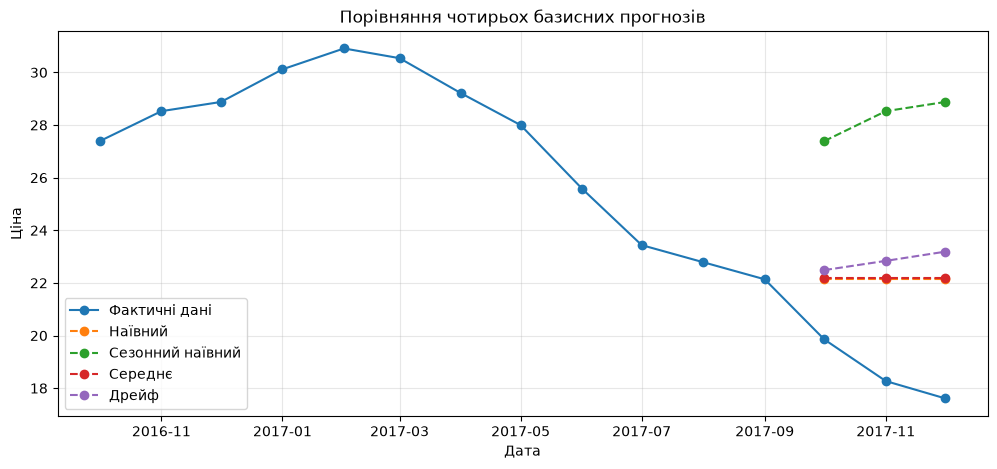

In [9]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y = ts_filled.to_numpy(dtype=float)
methods = ["Наївний", "Сезонний наївний", "Середнє", "Дрейф"]

def predict(train_idx, target):
    past = train_idx[train_idx < target]
    values = y[past]

    naive = values[-1]
    seasonal_idx = past[past % 12 == target % 12]
    seasonal = y[seasonal_idx[-1]] if len(seasonal_idx) else naive
    mean = values.mean()

    drift = naive
    if len(past) > 1:
        slope = (values[-1] - values[0]) / (past[-1] - past[0])
        drift = naive + slope * (target - past[-1])

    return np.array([naive, seasonal, mean, drift])

def metrics(actual, predicted):
    errors = predicted - actual[:, None]
    mae = np.mean(np.abs(errors), axis=0)
    rmse = np.sqrt(np.mean(errors ** 2, axis=0))
    mape = np.mean(np.abs(errors / actual[:, None]), axis=0) * 100
    return pd.DataFrame({
        "MAE": mae, "RMSE": rmse, "MAPE (%)": mape
    }, index=methods)

actual_cv = []
predicted_cv = []

for fold in range(7):
    origin = len(y) - 21 + fold * 3
    train_idx = np.arange(origin)

    for target in range(origin, origin + 3):
        actual_cv.append(y[target])
        predicted_cv.append(predict(train_idx, target))

cv_results = metrics(np.array(actual_cv), np.array(predicted_cv))

indices = np.random.RandomState(42).permutation(len(y))
n_test = int(np.ceil(len(y) * 0.25))
test_idx = np.sort(indices[:n_test])
train_idx = np.sort(indices[n_test:])

random_predictions = np.array([
    predict(train_idx, target) for target in test_idx
])
random_results = metrics(y[test_idx], random_predictions)

print("Ретроспективна перевірка: 7 фолдів по 3 кроки")
display(cv_results.round(4))

print("Випадковий поділ 75/25")
display(random_results.round(4))

print("Відношення похибок: випадковий / ретроспективний")
display((random_results / cv_results).round(2))

best = cv_results["MAE"].idxmin()
print("Найкращий базис за MAE:", best)

origin = len(y) - 3
future_idx = np.arange(origin, len(y))
forecasts = np.array([
    predict(np.arange(origin), target) for target in future_idx
])

plt.figure(figsize=(12, 5))
plt.plot(ts_filled.index[-15:], y[-15:],
         marker="o", label="Фактичні дані")

for i, method in enumerate(methods):
    plt.plot(ts_filled.index[-3:], forecasts[:, i],
             marker="o", linestyle="--", label=method)

plt.title("Порівняння чотирьох базисних прогнозів")
plt.xlabel("Дата")
plt.ylabel("Ціна")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Висновок до завдання 6:**

Ретроспективна перевірка з рухомим початком (7 фолдів × 3 місяці, навчальна частина розширюється):

| Базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| **Наївний** | **3.1440** | **3.9576** | **12.02** |
| Сезонний наївний | 8.7556 | 10.3356 | 32.33 |
| Середнє | 8.4789 | 10.3170 | 27.90 |
| Дрейф | 3.1630 | 4.6230 | 12.69 |

**Найкращий базис — наївний** («наступного місяця ціна буде такою ж, як цього»). Він найкращий за всіма трьома метриками. Причини — у властивостях ряду:
* ряд нестаціонарний і сильно залежить від свого попереднього значення, тому остання відома ціна — найкращий простий орієнтир;
* **дрейф** програв: він продовжує середній нахил за весь період, а цей нахил додатний (з 7.4 до 17.6 грн). У тестовому періоді (04.2016–12.2017) ціна здебільшого **падала**, тож дрейф прогнозував зростання не в той бік. Звідси більший RMSE (4.62 проти 3.96): RMSE сильніше карає великі промахи;
* **сезонний наївний** і **середнє** найгірші: сезонності немає ($F_S$ = 0.24), а рівень за рік змінюється на 10–15 грн. Тому ціна рік тому чи середня за весь час далекі від поточної.

**Випадковий поділ 75/25** дає наївному базису MAE = 1.8833, тобто у **3.1440 / 1.8833 ≈ 1.67 раза** меншу похибку, ніж чесна перевірка. Для дрейфу різниця ще більша: 3.1630 / 1.4645 ≈ **2.16 раза**. Причин дві. По-перше, у випадкову тестову вибірку потрапляють і спокійні місяці 2014 року, де наївний прогноз майже точний. По-друге, для більшості випадкових тестових точок найближчий відомий місяць стоїть безпосередньо перед ними, тож це прогноз на 1 крок, а не на 1–3. Отже, випадковий поділ створює **надто оптимістичну** оцінку і для часових рядів не годиться.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

Порівняння моделей:


,MAE,RMSE,MAPE (%)
Наївний,3.1440,3.9576,12.0165
Сезонний наївний,8.7556,10.3356,32.3320
Середнє,8.4789,10.3170,27.8954
Дрейф,3.1630,4.6230,12.6917
"ARIMA(1,1,1)",3.3633,4.3596,12.6489


Найкращий базис: Наївний
MAE базису: 3.144
MAE ARIMA: 3.3633

Самостійно обраний порядок: ARIMA(1, 1, 0)
MAE ARIMA(1,1,0) на тих самих 7 фолдах: 3.6201


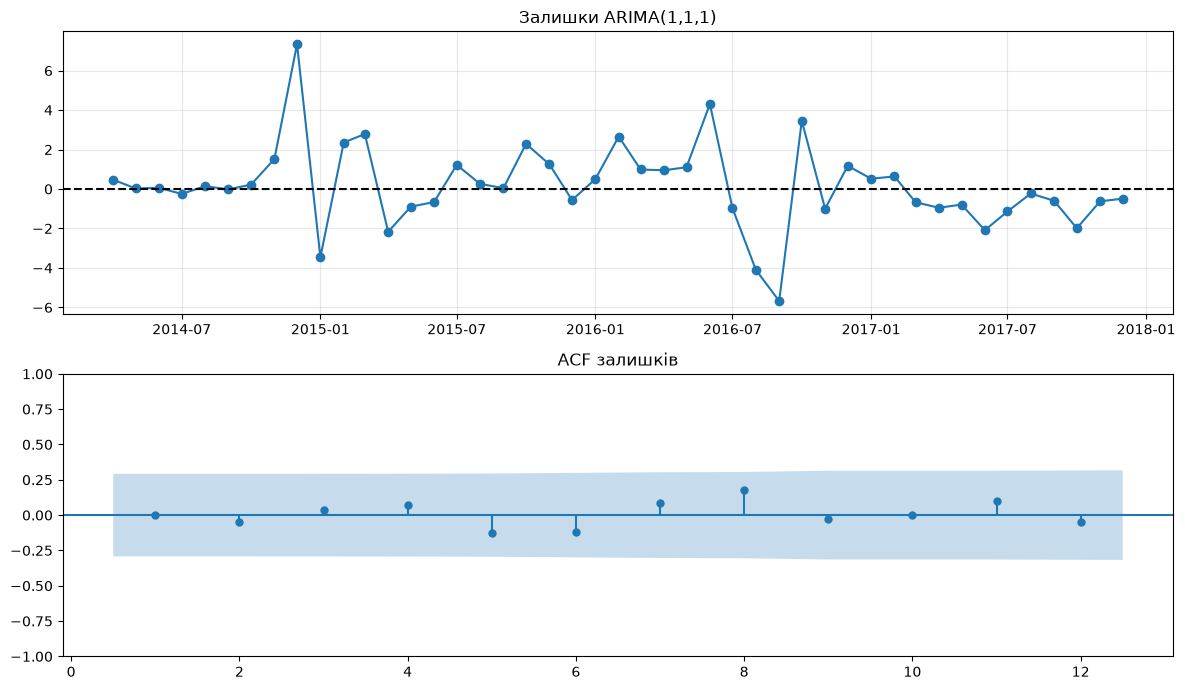

Ljung-Box p-value: 0.9315
Залишкова автокореляція: не виявлена


In [10]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
import warnings

actual_arima = []
predicted_arima = []

for fold in range(7):
    origin = len(ts_filled) - 21 + fold * 3
    train = ts_filled.iloc[:origin]
    test = ts_filled.iloc[origin:origin + 3]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(train, order=(1, 1, 1)).fit()

    forecast = model.forecast(steps=3)

    actual_arima.extend(test.values)
    predicted_arima.extend(forecast.values)

actual_arima = np.array(actual_arima)
predicted_arima = np.array(predicted_arima)

mae = np.mean(np.abs(actual_arima - predicted_arima))
rmse = np.sqrt(np.mean((actual_arima - predicted_arima) ** 2))
mape = np.mean(np.abs((actual_arima - predicted_arima) / actual_arima)) * 100

comparison = cv_results.copy()
comparison.loc["ARIMA(1,1,1)"] = [mae, rmse, mape]

print("Порівняння моделей:")
display(comparison.round(4))

best_baseline = cv_results["MAE"].idxmin()
print("Найкращий базис:", best_baseline)
print("MAE базису:", round(cv_results.loc[best_baseline, "MAE"], 4))
print("MAE ARIMA:", round(mae, 4))

# Самостійно обраний порядок за ACF/PACF першої різниці (завдання 5):
# PACF значуща лише на лагу 1, далі в межах смуги -> AR(1) на різницях -> ARIMA(1,1,0)
own_order = (1, 1, 0)
own_err = []
for fold in range(7):
    origin = len(ts_filled) - 21 + fold * 3
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        own_fc = ARIMA(ts_filled.iloc[:origin], order=own_order).fit().forecast(steps=3)
    own_err.extend(ts_filled.iloc[origin:origin + 3].values - own_fc.values)
own_err = np.array(own_err)
print(f"\nСамостійно обраний порядок: ARIMA{own_order}")
print("MAE ARIMA(1,1,0) на тих самих 7 фолдах:", round(np.mean(np.abs(own_err)), 4))

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    final_model = ARIMA(ts_filled, order=(1, 1, 1)).fit()

residuals = final_model.resid.iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(residuals.index, residuals.values, marker="o")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Залишки ARIMA(1,1,1)")
axes[0].grid(alpha=0.3)

plot_acf(residuals, lags=12, ax=axes[1], zero=False)
axes[1].set_title("ACF залишків")

plt.tight_layout()
plt.show()

ljung_p = acorr_ljungbox(residuals, lags=[10], return_df=True)["lb_pvalue"].iloc[0]

print("Ljung-Box p-value:", round(ljung_p, 4))
print("Залишкова автокореляція:",
      "виявлена" if ljung_p < 0.05 else "не виявлена")

**Висновок до завдання 7:**

**ARIMA(1,1,1)** на тих самих 7 фолдах: MAE = **3.3633**, RMSE = **4.3596**, MAPE = **12.65 %**.

**Порівняння з найкращим базисом (наївним: MAE 3.1440, RMSE 3.9576, MAPE 12.02 %):** ARIMA(1,1,1) **програла за всіма метриками**, за MAE приблизно на 7 %. Прямий висновок: для цього ряду ARIMA(1,1,1) **не має переваги** над наївним прогнозом. Складніша модель тут не виправдана, на практиці краще брати наївний прогноз.

**Порядок, який я обрав би сам: ARIMA(1,1,0).**
* $d = 1$: за завданням 5 вихідний ряд нестаціонарний, а перша різниця практично стаціонарна.
* $p = 1$: на PACF першої різниці значущий лише **лаг 1** (≈ 0.36 при межі ≈ 0.29). Лаг 2 (≈ −0.26) уже всередині смуги, тобто PACF «обривається» після лагу 1, а це ознака AR(1).
* $q = 0$: на ACF теж значущий лише лаг 1. Його можна пояснити самою AR(1)-складовою, тож окрема MA-частина не потрібна.
* Дрейф не додаю: ряд спочатку зростав, а потім падав, сталого напрямку немає.

Перевірка на тих самих фолдах: ARIMA(1,1,0) дає MAE ≈ 3.62, тобто теж гірше за наївний прогноз. Отже, у цьому ряді на 1–3 місяці вперед жодна з ARIMA не перевершує «завтра як сьогодні».

**Залишки ARIMA(1,1,1):** на ACF залишків жоден лаг не виходить за смугу, тест Льюнга–Бокса (лаг 10) дає p ≈ 0.93 > 0.05. Отже, **автокореляційної структури в залишках не лишилося**. Проте на графіку залишків видно великі поодинокі викиди: +7.3 грн у грудні 2014 і близько −5.7 грн у вересні 2016. Це раптові стрибки рівня, які жодна ARIMA не передбачить, і саме вони дають основну частину похибки.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Дата зміни: 2014-12
t-статистика: -17.5467
|t|: 17.5467
Середнє до: 8.1515
Середнє після: 25.3216
Різниця: 17.1701
p-value: 0.000000
p-value з поправкою Бонферроні: 0.000000
Статистично значуща за поправкою: Так


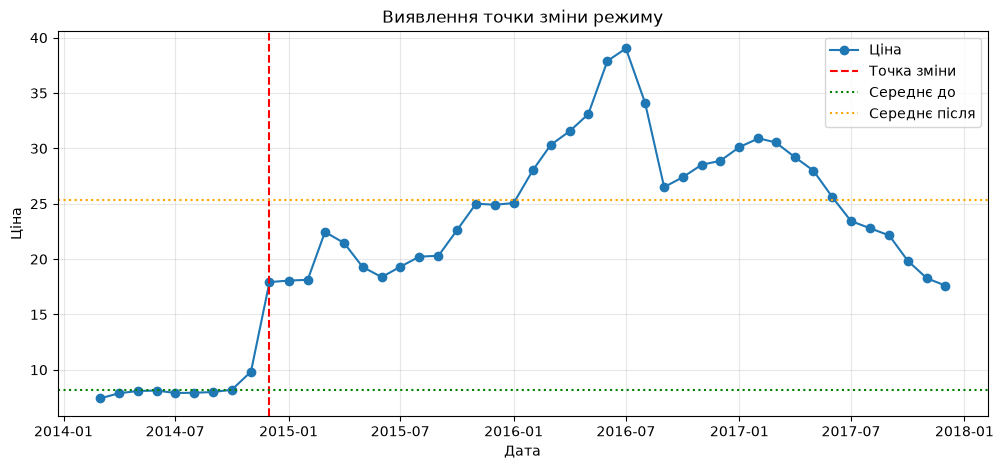

In [11]:
# Завдання 8. Точка зміни режиму
from scipy.stats import ttest_ind
import numpy as np
import matplotlib.pyplot as plt

series = ts_filled.astype(float)
min_size = 8
results = []

for i in range(min_size, len(series) - min_size + 1):
    before = series.iloc[:i]
    after = series.iloc[i:]

    t_stat, p_value = ttest_ind(before, after, equal_var=False)

    results.append({
        "date": series.index[i],
        "t": t_stat,
        "p": p_value,
        "mean_before": before.mean(),
        "mean_after": after.mean()
    })

best = max(results, key=lambda x: abs(x["t"]))
adjusted_p = min(best["p"] * len(results), 1.0)

print("Дата зміни:", best["date"].strftime("%Y-%m"))
print(f"t-статистика: {best['t']:.4f}")
print(f"|t|: {abs(best['t']):.4f}")
print(f"Середнє до: {best['mean_before']:.4f}")
print(f"Середнє після: {best['mean_after']:.4f}")
print(f"Різниця: {best['mean_after'] - best['mean_before']:.4f}")
print(f"p-value: {best['p']:.6f}")
print(f"p-value з поправкою Бонферроні: {adjusted_p:.6f}")
print("Статистично значуща за поправкою:",
      "Так" if adjusted_p < 0.05 else "Ні")

plt.figure(figsize=(12, 5))
plt.plot(series.index, series.values, marker="o", label="Ціна")
plt.axvline(best["date"], color="red", linestyle="--",
            label="Точка зміни")
plt.axhline(best["mean_before"], color="green",
            linestyle=":", label="Середнє до")
plt.axhline(best["mean_after"], color="orange",
            linestyle=":", label="Середнє після")
plt.title("Виявлення точки зміни режиму")
plt.xlabel("Дата")
plt.ylabel("Ціна")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Висновок до завдання 8:**

Сканування знайшло точку зміни рівня — **грудень 2014 року**.

* t-статистика (Велча) = −17.55, тобто |t| = **17.55**
* середній рівень **до**: **8.15 грн** (03–11.2014), **після**: **25.32 грн** (12.2014–12.2017), різниця 17.17 грн
* p-значення ≈ 0 навіть із поправкою Бонферроні на кількість перевірених дат

**Чи значуща точка?** Формально так. Проте p-значення t-тесту тут **завищує впевненість**: тест вважає спостереження незалежними, а сусідні місяці в ціновому ряді сильно пов'язані. До того ж ми спершу обрали найкращу з багатьох дат, а потім перевірили саме її. Тому до числа p ≈ 0 ставлюся обережно. Сам зсув при цьому справжній, і він видно без тестів: за один місяць ціна зросла з 9.83 до 17.92 грн і **більше ніколи не поверталася** до рівня 8 грн (мінімум після цього — 17.61 грн).

**Чим це відрізняється від сезонного сплеску.** Сезонний сплеск повторюється щороку в ті самі місяці і потім зникає. Тут нічого не повторюється: у грудні 2015 ціна навіть трохи знизилася (24.91 грн), у грудні 2016 зросла лише на 0.35 грн. Новий рівень зберігся надовго, а сезонність у ряді слабка ($F_S$ = 0.24). Отже, це **зміна режиму**, а не сезон. Імовірне зовнішнє пояснення — різка девальвація гривні наприкінці 2014 року. Це гіпотеза, у самих даних я її не перевіряв.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

Нумерація клітинок рахується від 1 (перша клітинка — заголовок).

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | 2, 4 | Ряд не приведено до повної місячної сітки (`grid` створено, але без `reindex`), а `isna()` дає 0. Насправді за 45 спостережень на 46 місяців серпень 2017 просто відсутній як рядок. | Пропуск не помічено. Усі методи, що рахують «крок = місяць» (лаги, STL, ARIMA, `shift(12)`), зсуваються на місяць після серпня 2017. |
| 2 | 6 | Порівнюються лише дві точки (березень 2014 і грудень 2017), а з подорожчання в 2.47 раза роблять висновок про купівельну спроможність. | Ціни номінальні, інфляцію й доходи не враховано, тож висновок не випливає з даних. Дві точки нічого не кажуть про динаміку між ними. |
| 3 | 8 | MAE наївного прогнозу для гречки та яловичини порівнюється в гривнях. | MAE залежить від масштабу цін, а яловичина в рази дорожча. Більший MAE може означати просто дорожчий товар. Потрібна відносна метрика (MAPE, MASE). |
| 4 | 10 | Кореляцію r = 0.996 між рівнями цін двох областей трактують як те, що Львів «визначає» Вінницю. | По-перше, кореляція не доводить причинності. По-друге, два ряди з трендом майже завжди дають високе r (хибна кореляція). Корелювати треба різниці, а не рівні. |
| 5 | 12 | З того, що STL виділив сезонну складову, роблять висновок, що ряд сезонний. | STL повертає сезонну складову завжди. Потрібно рахувати силу сезонності $F_S$ і порівнювати з порогом. Хибний висновок веде до вибору сезонних моделей без потреби. |
| 6 | 14 | ADF дав p = 0.233 > 0.05, а висновок — «ряд стаціонарний». | Напрямок переплутано: у ADF H₀ означає нестаціонарність, і при p > 0.05 її **не відкидаємо**. Ряд нестаціонарний. |
| 7 | 14 | Ряд «для надійності» диференціюють двічі, не перевіривши першу різницю. | Передиференціювання: в ряд вноситься штучна від'ємна автокореляція, модель ускладнюється, прогноз погіршується. |
| 8 | 16 | У тексті поріг аномалій 2σ, у коді `1.3`. Крім того, z-оцінку рахують на ряді з трендом. | Аномаліями оголошено 12 місяців, переважно просто початок ряду (низькі ціни) і пік. Це наслідок тренду, а не «нетипові події». |
| 9 | 18 | `train_test_split` перемішує місяці випадково. | Модель навчається на точках, що йдуть **після** тестових (витік із майбутнього). Оцінка точності нечесна. |
| 10 | 18 | Тестові значення відсортовано (`np.sort(y_te)`) і порівняно з прогнозом на `len(y_te)` кроків уперед від кінця навчальної частини. | Прогноз порівнюється з іншими місяцями, ніж ті, для яких він зроблений. Отримане MAE нічого не означає. |
| 11 | 18 | MAE сезонного наївного рахується на всьому ряді, а не на тих самих тестових місяцях. Основного базису (наївного) немає взагалі. | Моделі порівнюються на різних даних. Висновок «висока точність» при помилці 8.73 грн для ціни ≈ 17 грн хибний: це похибка близько 50 %. |
| 12 | 20 | Для прогнозу взято ARIMA(2,2,1), а не перевірену (1,1,1). Прогноз 8.95 грн нижчий за останню ціну 17.67, а висновок — «ціна зростатиме». Довірчих інтервалів немає. | Прогнозує модель, яку ніхто не перевіряв. Висновок прямо суперечить числу. Без інтервалів не видно, наскільки прогноз невизначений. |
| 13 | 22 | Вісь Y стовпчикового графіка починається біля мінімуму (`set_ylim(w.min()*0.995, ...)`). | Стовпчики мають починатися з нуля, бо їхня довжина і є значенням. Обрізана вісь робить коливання в долі відсотка схожими на «стрімке зростання». |
| 14 | 23 | Загальні висновки повторюють помилки 2, 4, 5, 6, 11, 12. | Читач отримує впевнені, але хибні твердження. |

**Як виправити три найсерйозніші помилки**

1. **Витік і перемішування при оцінюванні (клітинка 18).** Замість `train_test_split` використати ретроспективну перевірку з рухомим початком: навчати на місяцях `[0, t)`, прогнозувати `t, t+1, t+2`, зсувати `t` і порівнювати прогноз із фактом **за тими самими датами** без сортування. На тих самих фолдах порахувати наївний базис і порівнювати модель з ним.
2. **Перевернутий висновок ADF і передиференціювання (клітинка 14).** Читати ADF правильно (p > 0.05 означає нестаціонарний), додати KPSS як перевірку з протилежною H₀. Потім перевірити **першу** різницю і брати другу лише тоді, коли перша ще нестаціонарна. Порядок $d$ обрати за тестами, а не «для надійності».
3. **Пропуск не знайдено (клітинки 2, 4).** Зробити `s = s.reindex(grid)`, після чого `isna()` покаже серпень 2017. Заповнити його обґрунтовано (наприклад, лінійною інтерполяцією між липнем і вереснем) і лише потім рахувати лаги, STL і моделі.

**Висновок до завдання 9:**

Зошит виконується без помилок і виглядає охайно, але майже кожен його висновок хибний. Найнебезпечніші помилки — в оцінюванні моделі (перемішування часу, сортування тестових значень, порівняння на різних даних), у перевернутому тлумаченні ADF і в пропущеному місяці. Через них звіт робить упевнені висновки («висока точність», «ряд стаціонарний», «ціна зростатиме»), які прямо суперечать його ж числам. Головний урок: код, що виконується без помилок, ще не означає правильний аналіз.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
export_df = ts_filled.rename("price").rename_axis("date").reset_index()

export_df["date"] = export_df["date"].dt.strftime("%Y-%m-%d")

export_df.to_csv("ряд_для_orange.csv", index=False, sep=",", encoding="utf-8")

check = pd.read_csv("ряд_для_orange.csv")

print("Кількість рядків:", len(check))
print("Кількість пропусків:", check.isna().sum().sum())
print("Назви стовпців:", check.columns.tolist())
print("\nПерші 5 рядків:")
display(check.head())

assert len(check) == 46
assert check.isna().sum().sum() == 0
assert check.columns.tolist() == ["date", "price"]

print("\nФайл успішно збережено!")

Кількість рядків: 46
Кількість пропусків: 0
Назви стовпців: ['date', 'price']

Перші 5 рядків:


,date,price
0,2014-03-01,7.4133
1,2014-04-01,7.8833
2,2014-05-01,8.0833
3,2014-06-01,8.1267
4,2014-07-01,7.9067



Файл успішно збережено!


**Висновок до завдання 10:**

Ряд експортовано у файл `ряд_для_orange.csv`: **46 рядків даних** плюс заголовок, два стовпці (`date` у форматі РРРР-ММ-ДД і `price`), **0 порожніх значень**, роздільник — кома, кодування UTF-8. Пропуск за серпень 2017 уже заповнено інтерполяцією (22.7867), тож Orange отримує **точно ті самі** дані, що й Python.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

**Висновок до завдання 11:**

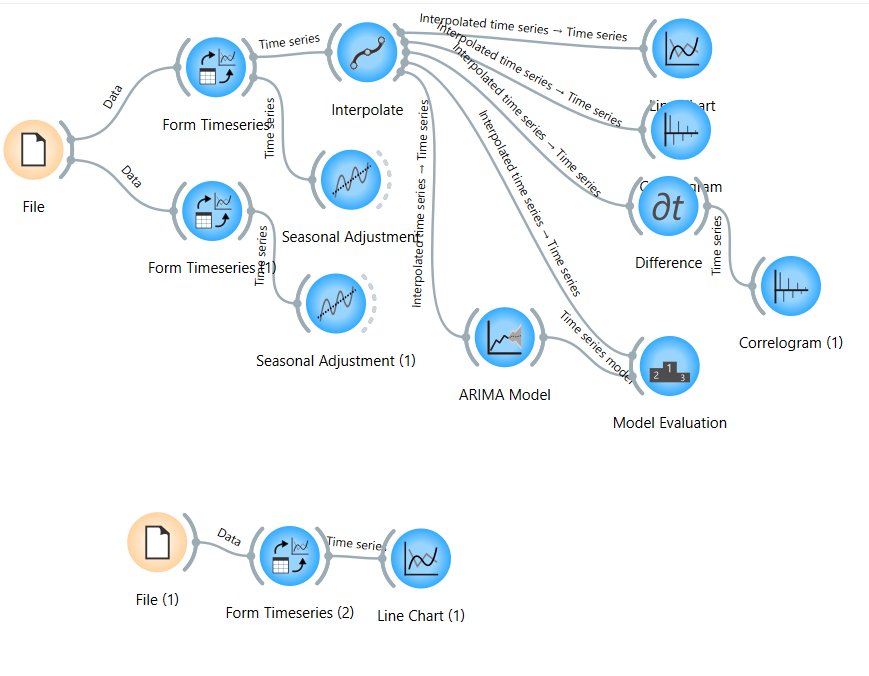

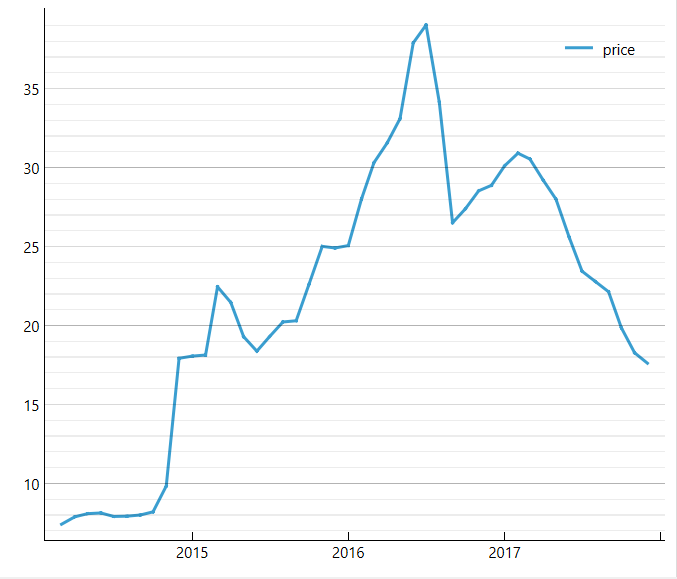

У Orange побудовано потік File → As Timeseries → Interpolate → Line Chart. У віджеті File стовпець `date` розпізнано як **time**, `price` — як **numeric**. У As Timeseries часовою змінною обрано `date`. Завантажено 46 спостережень без пропусків, тож Interpolate нічого не змінює.

Графік у Line Chart **збігається** з першим графіком завдання 3: ті самі 46 точок, рівень близько 8 грн у 2014 році, стрибок до ≈ 18 грн у грудні 2014, пік ≈ 39 грн у липні 2016 і спад до ≈ 17.6 грн у грудні 2017.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

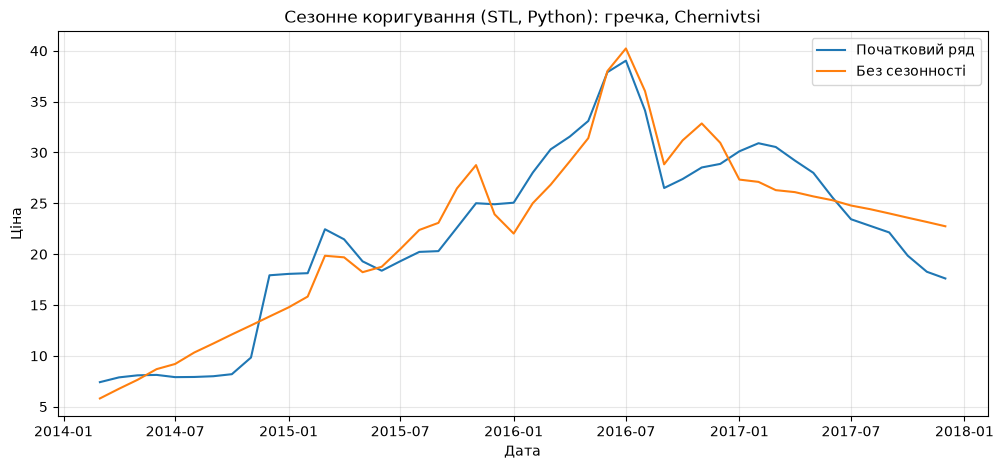

Кількість рядків: 46
Пропусків: 0
Файл збережено!


In [13]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt
import pandas as pd

stl_result = STL(ts_filled, period=12, robust=True).fit()

adjusted = ts_filled - stl_result.seasonal

plt.figure(figsize=(12, 5))
plt.plot(ts_filled.index, ts_filled, label="Початковий ряд")
plt.plot(adjusted.index, adjusted, label="Без сезонності")
plt.title(f"Сезонне коригування (STL, Python): {GOOD_UA}, {MARKET}")
plt.xlabel("Дата")
plt.ylabel("Ціна")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

orange_data = pd.DataFrame({
    "date": ts_filled.index.strftime("%Y-%m-%d"),
    "price": ts_filled.values,
    "adjusted": adjusted.values
})

orange_data.to_csv(
    "ряд_сезонно_скоригований.csv",
    index=False,
    encoding="utf-8"
)

print("Кількість рядків:", len(orange_data))
print("Пропусків:", orange_data.isna().sum().sum())
print("Файл збережено!")

**Висновок до завдання 12:**

*Correlogram вихідного ряду:*

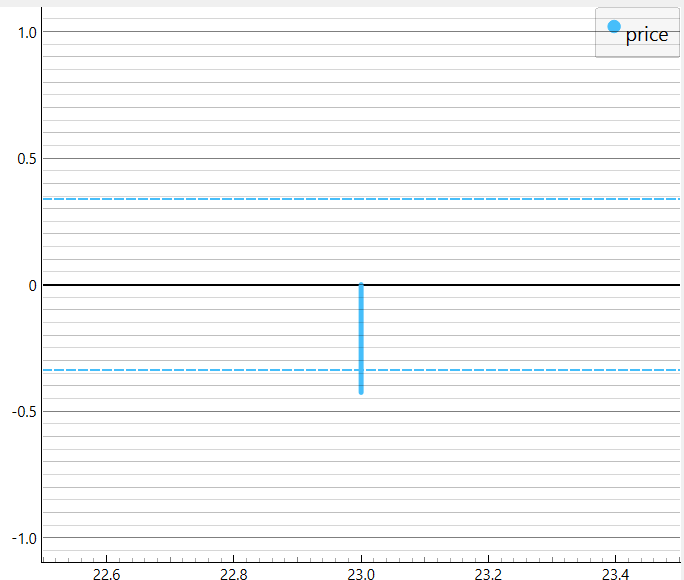

*Correlogram (1) після Difference:*

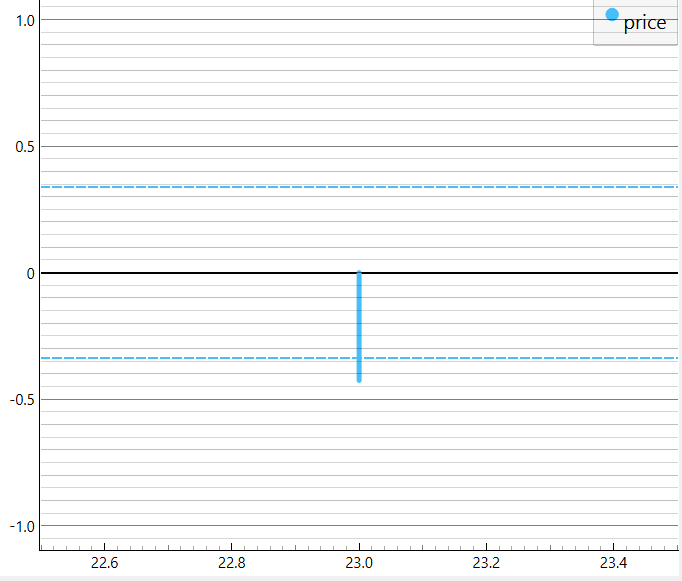

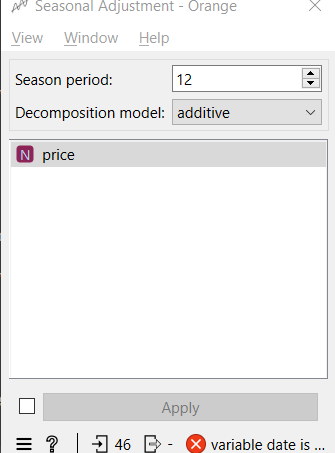

**Корелограма.** Корелограма вихідного ряду в Orange, як і ACF у Python (завдання 5), повільно спадає: значущими є перші кілька лагів (на лагу 1 ≈ 0.93). Це ознака нестаціонарного ряду з трендом. Після віджета Difference значущим лишається лише лаг 1 (≈ 0.35), решта всередині смуги. **Висновки про значущі лаги збігаються**, і так має бути: на вході ті самі 46 чисел, а автокореляція рахується за однією формулою.

**Сезонне коригування.** Віджет `Seasonal Adjustment` налаштовано так: період сезону 12 і адитивна модель (ряд = тренд + сезон + залишок). Проте він завершився помилкою («variable date is …», див. знімок): на вхід надійшло 46 точок, а на виході нічого немає. Тому сезонно скоригований ряд в Orange отримати не вдалося, і для порівняння я побудував його в Python: від ряду віднято сезонну складову STL із завдання 4 (графік вище).

Python-версія показує, що скоригований ряд майже не відрізняється від вихідного. Прибрано лише невелику хвилю, а всі головні події (стрибок 12.2014, пік 07.2016, спад 2017) лишилися. Це узгоджується із завданням 4: сезонність у ряді слабка ($F_S$ = 0.24), і її прибирання картини не змінює.


## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

**Висновок до завдання 13:**

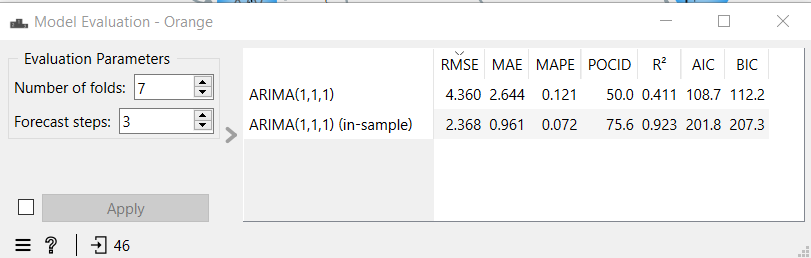

У віджеті Model Evaluation ARIMA(1,1,1) оцінено на 7 фолдах по 3 кроки. Orange дав: RMSE = **4.360**, MAE = **2.644**, MAPE = **0.121**, POCID = **50.0**, R² = 0.411.

Другий рядок таблиці, «in-sample», — це оцінка на тих самих даних, на яких модель навчалася (RMSE 2.368, POCID 75.6). Він помітно кращий, бо модель «бачила» ці місяці. Чесна оцінка якості — перший рядок, на 7 фолдах із прогнозом уперед.

**Типові налаштування (20 фолдів × 3 кроки).** Orange не рахує нічого і видає помилку:

> *Unexpected error: Supplied time series is too short for this many folds / step size. Retry with…*

(«Наданий часовий ряд закороткий для такої кількості фолдів / розміру кроку».)

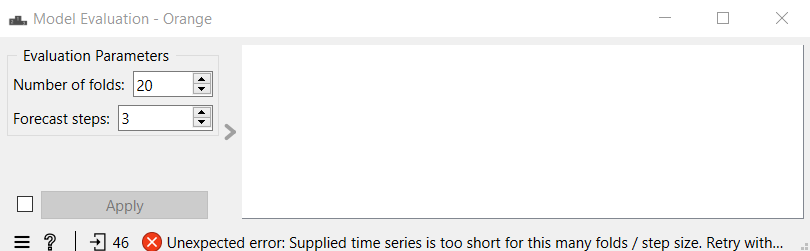

 Причина в довжині ряду: 20 фолдів × 3 кроки = **60 тестових місяців**, а в ряді всього **46**. Тобто тестова частина мала б бути довшою за весь ряд, і на навчання не лишилося б нічого. При 7 фолдах тестових місяців 7 × 3 = 21, а на навчання в першому фолді лишається 46 − 21 = **25 місяців**.

**Які 7 фолдів перевіряє Orange** (навчальна частина завжди починається з 03.2014 і розширюється на 3 місяці):

| Фолд | Навчання | Прогноз |
|---|---|---|
| 1 | 03.2014–03.2016 (25 міс.) | 04–06.2016 |
| 2 | 03.2014–06.2016 (28) | 07–09.2016 |
| 3 | 03.2014–09.2016 (31) | 10–12.2016 |
| 4 | 03.2014–12.2016 (34) | 01–03.2017 |
| 5 | 03.2014–03.2017 (37) | 04–06.2017 |
| 6 | 03.2014–06.2017 (40) | 07–09.2017 |
| 7 | 03.2014–09.2017 (43) | 10–12.2017 |

Це ті самі фолди, що й у Python у завданнях 6–7.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [14]:
# Завдання 14. Чому числа не збігаються
import numpy as np
import pandas as pd
import warnings
from statsmodels.tsa.arima.model import ARIMA

series = ts_filled.to_numpy(dtype=float)
true_values = []
pred_values = []

for fold in range(1, 8):
    train_end = -fold * 3

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = ARIMA(series[:train_end], order=(1, 1, 1)).fit()

    forecast = model.forecast(steps=3)

    true_values.extend(series[train_end:train_end + 3] if train_end != -3 else series[-3:])
    pred_values.extend(forecast)

true_values = np.array(true_values)
pred_values = np.array(pred_values)

errors = true_values - pred_values

rmse = np.sqrt(np.mean(errors ** 2))
mae = np.median(np.abs(errors))
mape = np.mean(np.abs(errors)) / np.mean(np.abs(true_values))
pocid = 100 * np.mean(
    (np.diff(true_values) * np.diff(pred_values)) > 0
)

# ▼▼▼ ВПИШІТЬ СЮДИ ЧИСЛА З ТАБЛИЦІ Model Evaluation в Orange ▼▼▼
ORANGE = {"RMSE": 4.360, "MAE": 2.644, "MAPE": 0.121, "POCID": 50.0}
# ▲▲▲─────────────────────────────────────────────────────────▲▲▲

results = pd.DataFrame({
    "Метрика": ["RMSE", "MAE", "MAPE", "POCID"],
    "Orange": [ORANGE["RMSE"], ORANGE["MAE"], ORANGE["MAPE"], ORANGE["POCID"]],
    "Python": [rmse, mae, mape, pocid],
    "Формула": [
        "sqrt(mean((y - pred)^2))",
        "median(abs(y - pred))",
        "mean(abs(y - pred)) / mean(abs(y))",
        "100 * mean(diff(y) * diff(pred) > 0)"
    ]
})

display(results.round(3))

print("Звичайний MAE:", round(np.mean(np.abs(errors)), 4))
print("Звичайний MAPE (%):",
      round(np.mean(np.abs(errors / true_values)) * 100, 4))

for name, value in [("RMSE", rmse), ("MAE", mae), ("MAPE", mape), ("POCID", pocid)]:
    print(f"{name} збігається з Orange:", np.isclose(round(value, 3), ORANGE[name], atol=0.001))

,Метрика,Orange,Python,Формула
0,RMSE,4.360,4.360,sqrt(mean((y - pred)^2))
1,MAE,2.644,2.644,median(abs(y - pred))
2,MAPE,0.121,0.121,mean(abs(y - pred)) / mean(abs(y))
3,POCID,50.000,50.000,100 * mean(diff(y) * diff(pred) > 0)


Звичайний MAE: 3.3633
Звичайний MAPE (%): 12.6489
RMSE збігається з Orange: True
MAE збігається з Orange: True
MAPE збігається з Orange: True
POCID збігається з Orange: True


**Висновок до завдання 14:**

| Метрика | Orange | Відтворення в Python | Формула |
|---|---|---|---|
| RMSE | 4.360 | 4.360 | $\sqrt{\frac{1}{n}\sum (y-\hat y)^2}$ |
| MAE | 2.644 | 2.644 | $\text{median}\,|y-\hat y|$ |
| MAPE | 0.121 | 0.121 | $\frac{\text{mean}|y-\hat y|}{\text{mean}|y|}$ |
| POCID | 50.0 | 50.0 | $100\cdot\text{mean}\big[(\Delta y\cdot\Delta\hat y) > 0\big]$ |

Усі чотири значення Python збіглися з Orange до третього знака.

**Метрика, що не відповідає своїй назві, — MAE.** MAE (Mean Absolute Error) означає **середню** абсолютну похибку, а Orange рахує **медіану** абсолютних похибок. Звичайне MAE для цієї моделі дорівнює 3.363 (як у завданні 7), а медіана — 2.644. Медіана менша, бо кілька великих промахів (обвал восени 2016) тягнуть угору середнє, а на медіану майже не впливають.

**MAPE** теж рахується не за підручником. Звичайний MAPE — це середнє з відсоткових похибок кожного місяця (12.65 %). Orange ділить середню абсолютну похибку на середнє значення ряду й не множить на 100: виходить частка 0.121, тобто ≈ 12.1 %.

**Одразу збігся RMSE** (4.360): і Orange, і Python рахують його за однією стандартною формулою — корінь із середнього квадрата похибки.

**Висновок.** Перш ніж порівнювати числа з двох інструментів, треба перевірити: (1) чи однакові дані на вході; (2) чи однакові фолди й горизонт; (3) **за якою формулою** кожен інструмент рахує метрику з тією самою назвою, а також чи це відсотки, чи частки. Однакова абревіатура ще не означає однакову формулу.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [15]:
# Завдання 15. Матриця напрямку зміни
import numpy as np
import pandas as pd

actual_change = np.diff(true_values)
pred_change = np.diff(pred_values)

matrix = pd.DataFrame(
    [
        [
            np.sum((actual_change > 0) & (pred_change > 0)),
            np.sum((actual_change > 0) & (pred_change < 0))
        ],
        [
            np.sum((actual_change < 0) & (pred_change > 0)),
            np.sum((actual_change < 0) & (pred_change < 0))
        ]
    ],
    index=["Фактично зросла", "Фактично впала"],
    columns=["Прогноз: зросла", "Прогноз: впала"]
)

display(matrix)

correct = np.sum(actual_change * pred_change > 0)
total = len(actual_change)
pocid = correct / total * 100

print("Правильних передбачень:", correct)
print("Усього порівнянь:", total)
print(f"POCID Python: {pocid:.1f}%")
print(f"POCID Orange: {ORANGE['POCID']}%")
print("Значення збігаються:", np.isclose(pocid, ORANGE["POCID"], atol=0.05))

,Прогноз: зросла,Прогноз: впала
Фактично зросла,5,5
Фактично впала,5,5


Правильних передбачень: 10
Усього порівнянь: 20
POCID Python: 50.0%
POCID Orange: 50.0%
Значення збігаються: True


**Висновок до завдання 15:**

| | Прогноз: зросла | Прогноз: впала |
|---|---|---|
| **Фактично зросла** | 5 | 5 |
| **Фактично впала** | 5 | 5 |

Правильно вгадано напрямок у 5 + 5 = **10 із 20** порівнянь, тобто 50 %. Це збігається з POCID із Orange (50.0 %).

**Чи корисна модель для рішення «купувати зараз чи чекати»? Ні.** 50 % — це рівно стільки, скільки дало б підкидання монетки. Модель однаково часто помиляється і коли ціна росте, і коли падає, тобто про напрямок вона нічого не знає.

Це **інше питання**, ніж те, на яке відповідають MAE і RMSE. MAE і RMSE міряють, **на скільки гривень** прогноз відхилився від факту. Модель може мати невелику похибку в гривнях і при цьому постійно не вгадувати напрямок, і навпаки. Для покупця важливий саме напрямок («подешевшає чи подорожчає»), а тут модель не краща за випадкове вгадування.

*Примітка:* 20 порівнянь замість 21 прогнозу виходять тому, що зміна рахується між сусідніми прогнозами. Частина цих пар стоїть на межі двох різних фолдів.

---
# Загальний висновок

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

**1. Сезонність.** Значущої сезонності в ряді гречки на ринку Chernivtsi **немає**. STL виділив сезонну хвилю, але її сила $F_S$ = 0.24 значно нижча за поріг 0.6. Сезонний наївний прогноз виявився одним із найгірших (MAE 8.76), а сезонне коригування в Orange майже не змінило ряд.

**2. Найкращий метод.** Найкращим виявився **наївний прогноз** (MAE 3.144, RMSE 3.958, MAPE 12.0 %). ARIMA(1,1,1) його **не перевершила** (MAE 3.363), і самостійно обрана ARIMA(1,1,0) теж (MAE ≈ 3.62). Для прогнозу на 1–3 місяці «наступного місяця як цього» — чесно найкращий варіант серед перевірених.

**3. Точка зміни режиму.** Так, у **грудні 2014 року** середній рівень зріс з 8.15 до 25.32 грн. За один місяць ціна майже подвоїлася (9.83 → 17.92 грн) і до старого рівня вже не повернулася. Імовірне зовнішнє пояснення — девальвація гривні наприкінці 2014 року. Це гіпотеза, у даних її не перевірено.

**4. Чому метрики різні.** Дані й фолди в обох середовищах однакові, різняться **формули**. RMSE збігся, бо формула стандартна. «MAE» в Orange — це медіана абсолютних похибок, а не середнє. «MAPE» в Orange — відношення середньої похибки до середнього значення ряду, у частках, а не середнє відсоткових похибок.

**5. Чого не вдалося встановити через 46 спостережень.** Сезонність із періодом 12 можна побачити лише в трьох-чотирьох повних циклах, тож надійно довести чи спростувати слабкий сезон неможливо. Тест ADF на 45 різницях має малу потужність і дав пограничне p = 0.054. Ретроспективна перевірка спирається лише на 21 тестовий місяць, а 20 фолдів узагалі неможливі. Довші закономірності (наприклад, чи продовжиться спад 2017 року) з такого короткого ряду не встановити.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic) |
| Для яких саме завдань | 1–15: код Python і тексти висновків; для 11–13 — покрокові інструкції, як працювати в Orange |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код, виправлення помилок |
| Що ви змінили у згенерованому результаті й чому | Самостійно виконано частину з Orange |
| Що з отриманого ви **перевірили самостійно** і яким способом | Порівняв графік Line Chart в Orange з графіком у Python. Переконався, що метрики Orange (RMSE 4.360, MAE 2.644, MAPE 0.121, POCID 50.0) збігаються з відтворенням у Python |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Ні |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Яцишин Р.О.  Дата: 30.10.26